# Problem
Recover wavelength-dependent RGB camera responses from real direct and grating-dispersed images. Four cameras provide distinct measured acquisitions, not synthetic repeats. The unknown is the response curve, not a sharpened photograph. Unknown throughput and mapping make this an inverse calibration problem.

In [1]:
from pathlib import Path
import os,sys,time,numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,CAMERAS
from src.solvers import reconstruct
from src.visualization import *
data=load_data()
truth=np.load('evaluation/ground_truth.npz',allow_pickle=False)['reconstruction']
upstream=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)['reconstruction']

## Data
The observations are author-decoded real RAW-image crops. Independent CamSPECS measurements at the exact 31 output wavelengths are actual reference measurements; they are not used in the reconstruction. The 44-camera population is a separate prior. Fluorescent and LED source spectra are calibrated inputs. No absolute gain, per-file exposure or calibrated noise law is available.

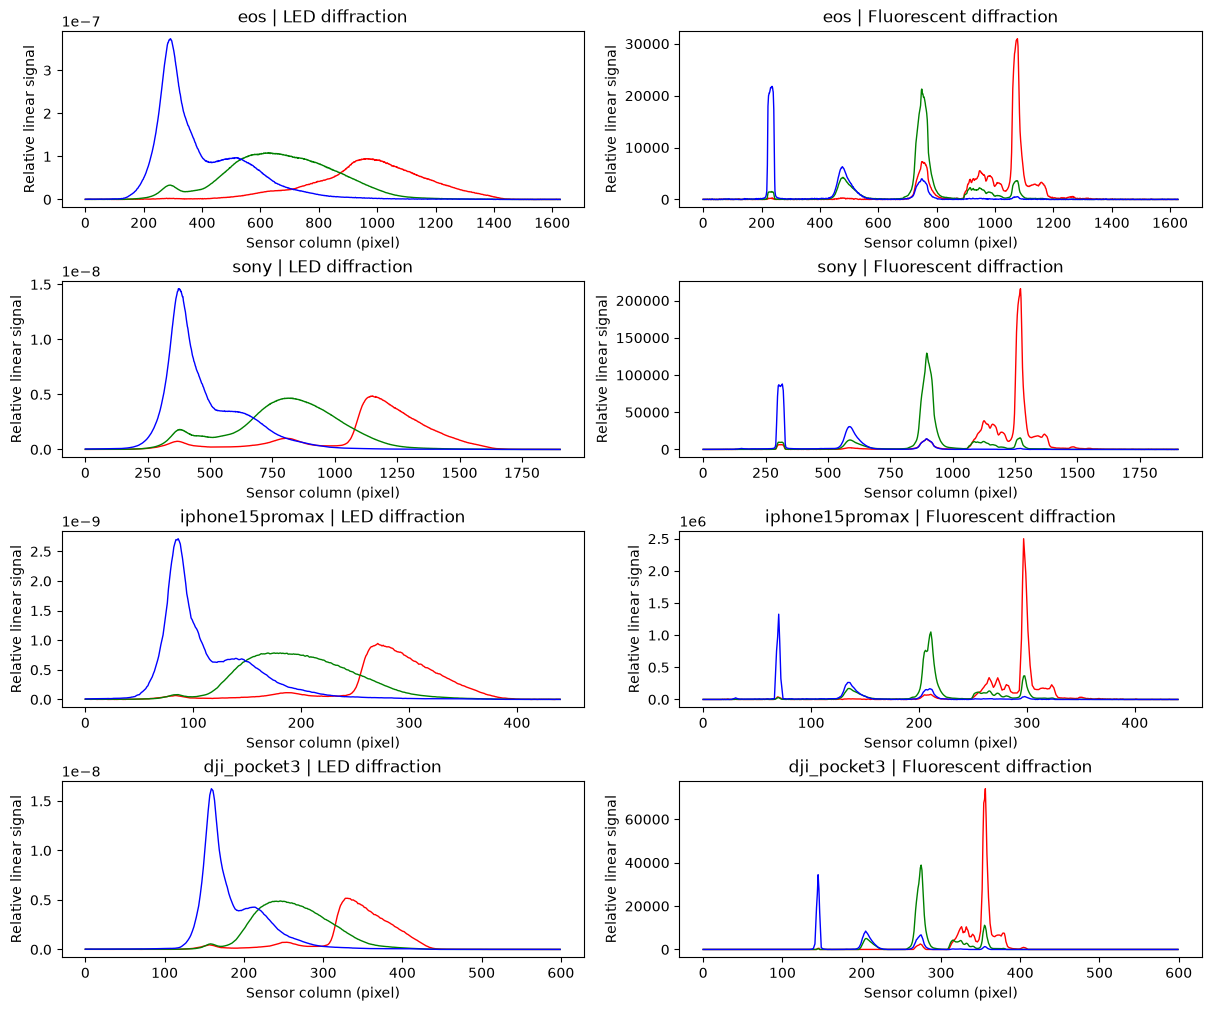

In [2]:
observations_figure(data);plt.show()

## Physics
Each direct RGB value integrates illumination times sensitivity. A diffraction profile additionally multiplies by unknown grating throughput and a pixel/wavelength mixing matrix. The response is only relatively identifiable. Linear interpolation maps 31 unknown spectral samples to 321 illumination samples. Finite support and endpoint extrapolation follow the original discretization; no hidden-target calibration is supplied.

For channel c, sensor pixel p and spectral sample j:

$$d_c=\sum_j l_j s_{jc},\qquad y_{pc}=\sum_j K_{pj}(w)l_j a_j s_{jc}.$$

Here d is direct RGB, y the dispersed profile, l the measured LED spectrum, s the response interpolated to the illumination grid, a the unknown relative throughput, K the wavelength mixing operator and w the pixel mapping. Bin scale is absorbed into relative sensitivity.


## Method
The seven-mode uncentred population basis restricts camera responses. Six fluorescent peak correspondences fit a quadratic pixel map. Reciprocal-throughput expansion converts the joint fit into constrained linear least squares, with direct RGB measurements enforcing channel scale. A local KKT solve implements the original method. All results below are actively recomputed from observations; the archived original reconstruction is used only as an independently identified comparison.
With x concatenating reciprocal-throughput and spectral-basis coefficients, normalized residual matrix A, direct-observation constraint matrix C, measured direct vector d and multipliers mu, solve

$$\begin{bmatrix} A^TA & C^T \\ C & 0 \end{bmatrix}\begin{bmatrix}x\\\mu\end{bmatrix}=\begin{bmatrix}0\\d\end{bmatrix}.$$

This is equality-constrained least squares. The seven Fourier throughput modes and seven population modes per channel are fixed before fitting. No target response enters A, C or d. The default branch is a closed-form solve; the LED-only comparison has 500 mapping updates.


Fresh four-camera reconstruction seconds: 0.19301699998322874


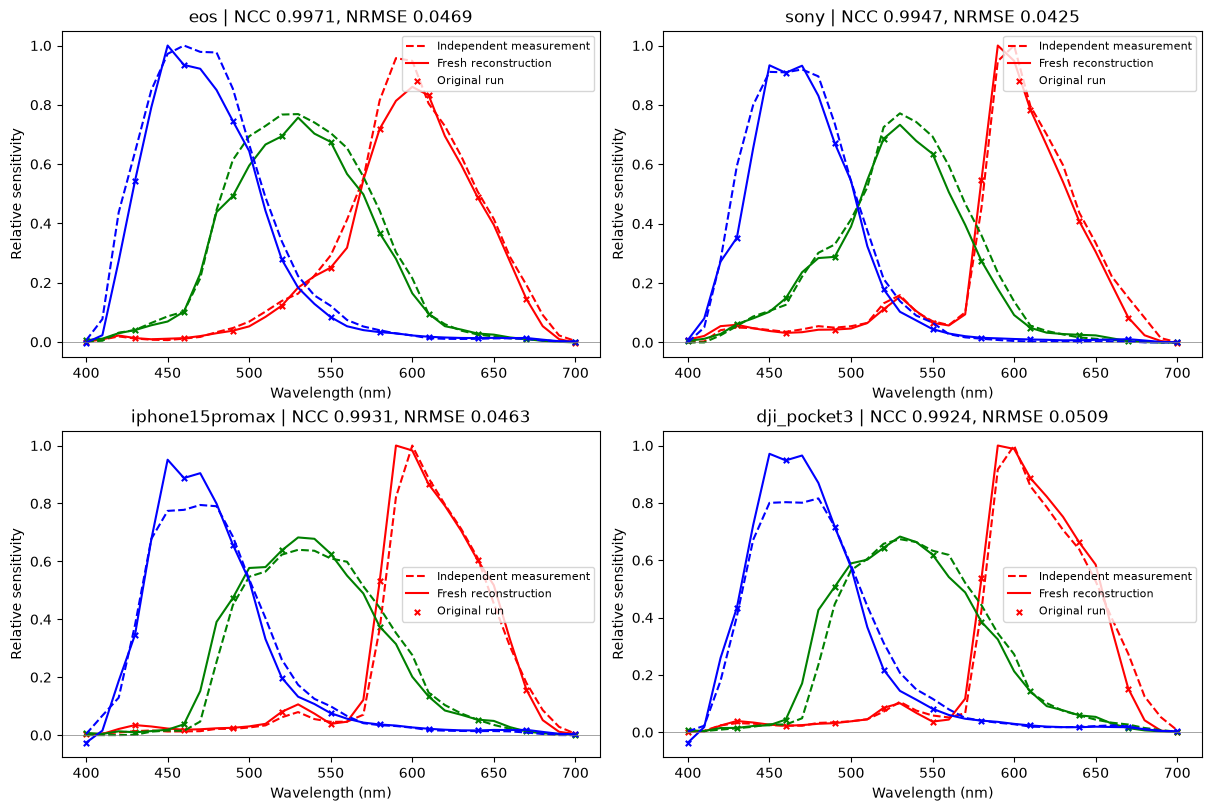

In [3]:
start=time.perf_counter()
result,details=reconstruct(data)
print('Fresh four-camera reconstruction seconds:',time.perf_counter()-start)
response_figure(result,truth,upstream);plt.show()

## Results
Solid curves are fresh local results; dashed curves are independent response measurements; crosses are the independently executed original estimator. The displayed metrics use actual measured samples, cosine NCC and dynamic-range NRMSE. The original paper relative-error calculation uses a projected extended grid and a different normalization, so those numbers are not interchangeable.

eos {'ncc': 0.99708482204059, 'dynamic_range_nrmse': 0.046906696816561434}
sony {'ncc': 0.9946611531596031, 'dynamic_range_nrmse': 0.042515275446635366}
iphone15promax {'ncc': 0.9931358681067366, 'dynamic_range_nrmse': 0.046300454079633985}
dji_pocket3 {'ncc': 0.9924097949136663, 'dynamic_range_nrmse': 0.050943168939554376}


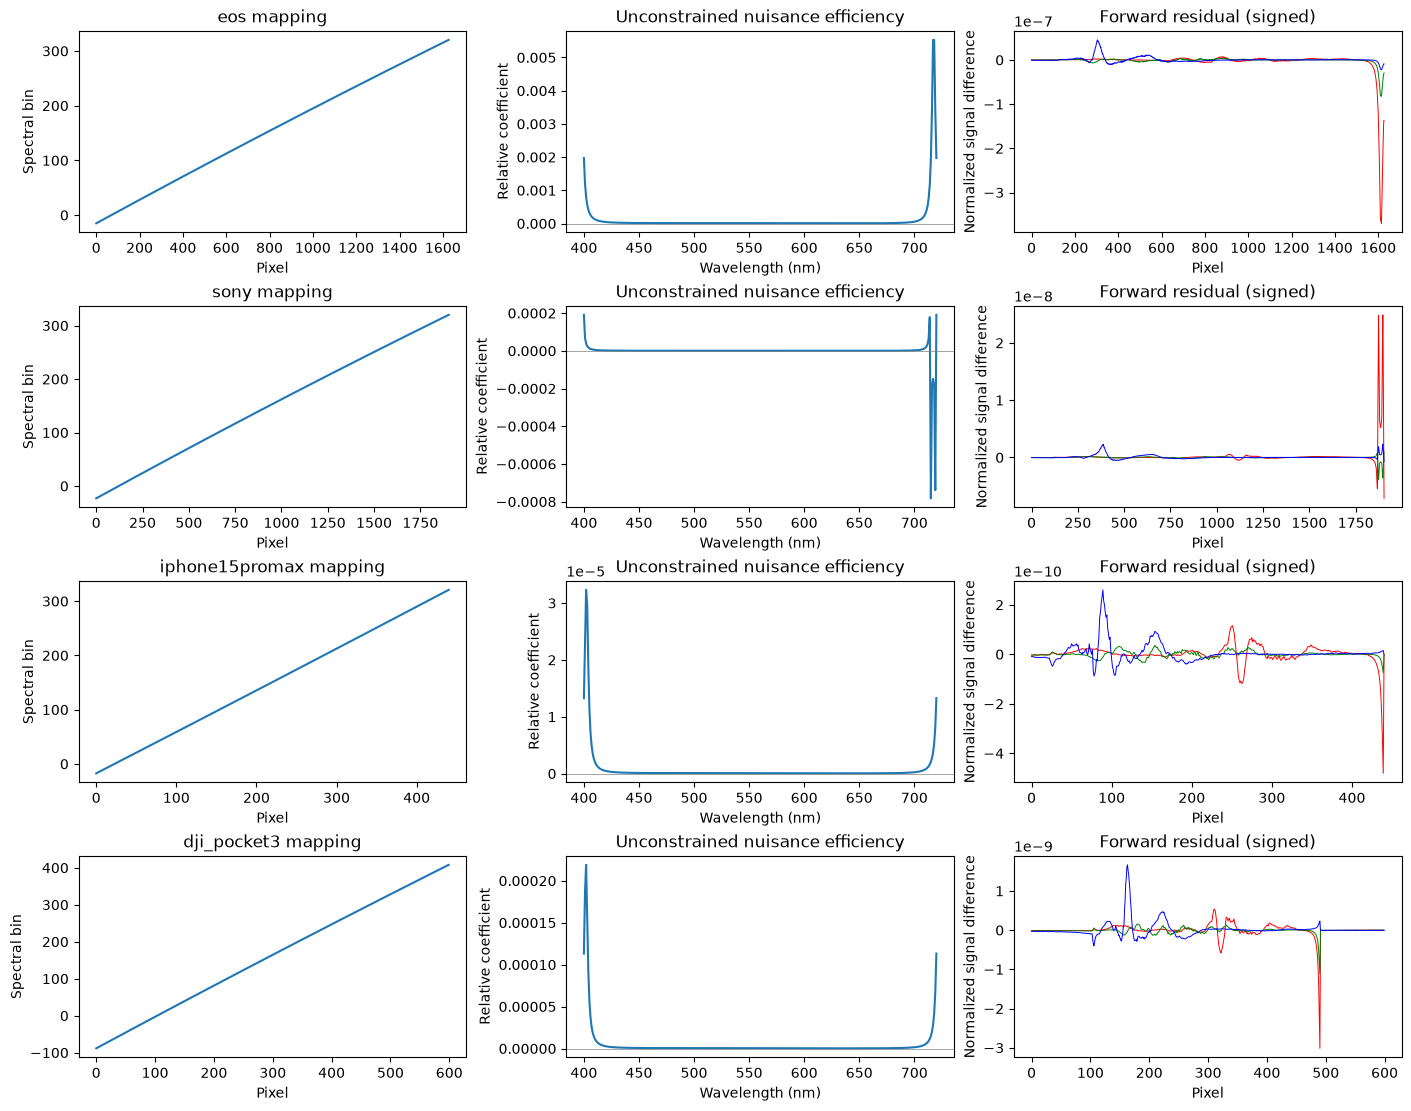

In [4]:
for i,c in enumerate(CAMERAS): print(c,dict(zip(('ncc','dynamic_range_nrmse'),metrics(result[0,i],truth[0,i]))))
diagnostic_figure(details);plt.show()

### Physical diagnostic
Signed throughput and residuals are deliberately retained. The unconstrained expansion can produce negative nuisance throughput, especially for Sony. A successful response fit does not validate that quantity as a physical grating efficiency. These panels expose model limitations rather than clipping them away.

LED only seconds 3.6935816999757662


Response basis 5 seconds 0.3917535999789834


Response basis 9 seconds 0.39292430004570633


Throughput basis 3 seconds 0.4082624999573454


Throughput basis 5 seconds 0.3906919000437483


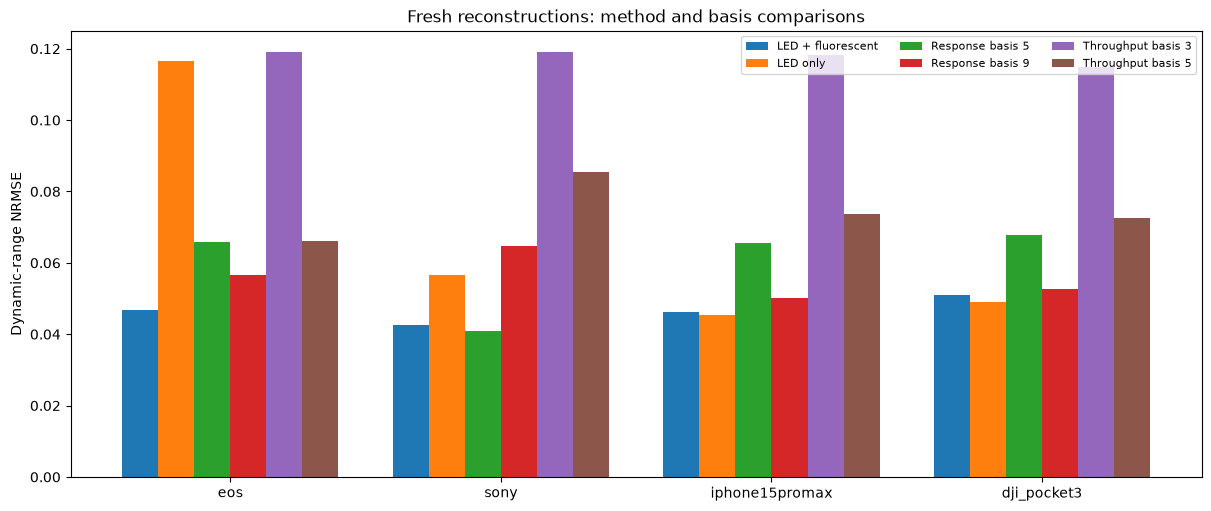

In [5]:
variants={'LED + fluorescent':result}
for name,kw in [('LED only',dict(fluorescent=False)),('Response basis 5',dict(basis_size=5)),('Response basis 9',dict(basis_size=9)),('Throughput basis 3',dict(attenuation_size=3)),('Throughput basis 5',dict(attenuation_size=5))]:
    tick=time.perf_counter();variants[name]=reconstruct(data,**kw)[0];print(name,'seconds',time.perf_counter()-tick)
comparison_figure(variants,truth);plt.show()

### Method and basis comparisons
All twenty alternative camera reconstructions above were freshly computed. The LED-only branch replaces fluorescent peak matching with the original fixed-iteration point-to-plane mapping. Basis changes test the bias/ambiguity of the low-dimensional prior. These are parameter studies, not independent new acquisitions. The paper also compares color-checker and EXIF-assisted approaches; their exact bound inputs are not distributed here, so no invented fresh baseline is plotted.

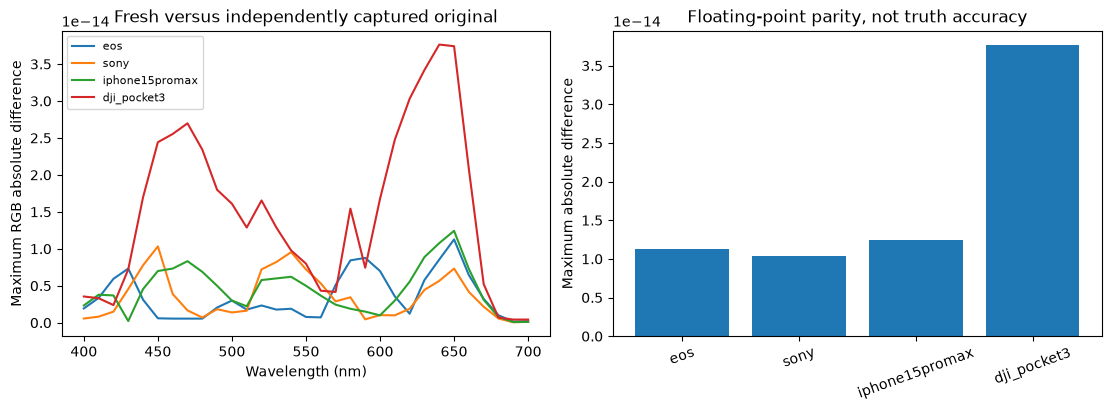

In [6]:
parity_figure(result,upstream);plt.show()

### Supplementary perturbations
These are synthetic robustness perturbations of the real images, not additional measured acquisitions or a calibrated noise model. Seed 42 and relative signal levels are fixed. The independent response measurements remain unchanged.

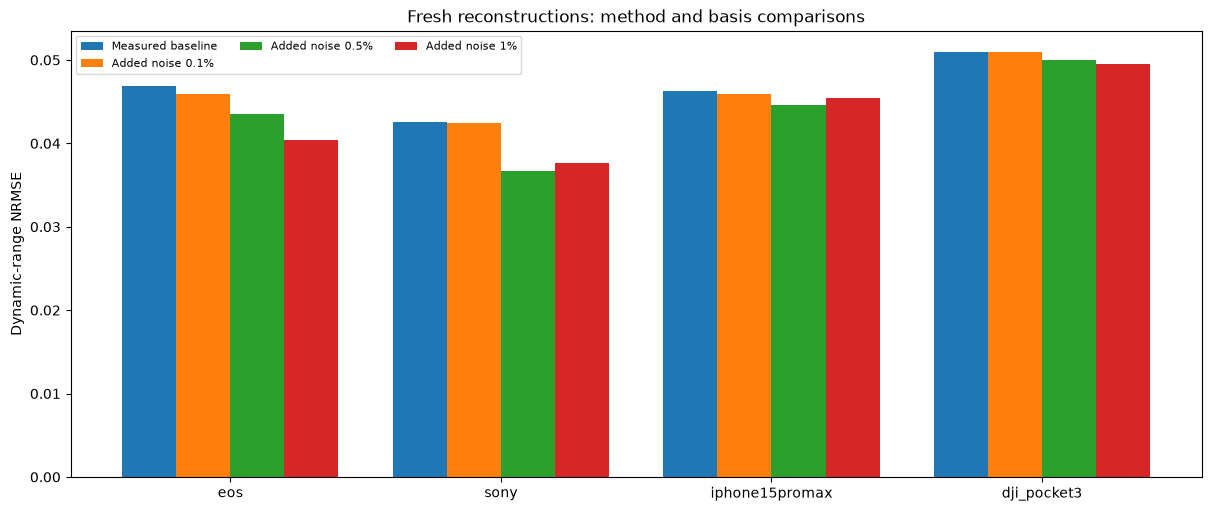

In [7]:
rng=np.random.default_rng(42)
noise_results={'Measured baseline':result}
for level in (.001,.005,.01):
    perturbed={k:v.copy() for k,v in data.items()}
    for camera in CAMERAS:
        for suffix in ('direct','diffracted','fluorescent'):
            key=camera+'_'+suffix;arr=perturbed[key]
            perturbed[key]=arr.astype(float)+rng.normal(0,level*float(arr.max()),arr.shape)
    noise_results[f'Added noise {100*level:g}%']=reconstruct(perturbed)[0]
comparison_figure(noise_results,truth);plt.show()


## Conclusion
Measured dispersed illumination can recover the four camera response shapes with independently assessed error. The original/local comparison establishes numerical extraction parity, while the separate CamSPECS measurements assess response accuracy. Neither proves physically valid nuisance throughput. Absolute radiometry and uncertainty from a calibrated sensor-noise model remain unavailable. The population prior, illumination spectrum and mapping assumptions limit generalization to other instruments.
The single seeded perturbation study is a sensitivity diagnostic, not an uncertainty interval. Some added noise reduces error relative to this particular reference; this does not establish that adding noise improves calibration generally.